In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect(":memory:")

con.execute("""
CREATE TABLE customers (
    id INTEGER PRIMARY KEY,
    name TEXT,
    city TEXT,
    total_spent REAL
)
""")

customers = [
    (1, "Alex Kim", "Los Angeles", 250.50),
    (2, "Jordan Lee", "San Diego", 180.25),
    (3, "Taylor Park", "Irvine", 320.00),
    (4, "Morgan Chen", "Santa Monica", 145.75),
    (5, "Sam Rivera", "Long Beach", 410.20),
    (6, "Casey Johnson", "Pasadena", 95.50),
    (7, "Jamie Brown", "Torrance", 275.00),
    (8, "Riley Davis", "Culver City", 195.80)
]

con.executemany("""
INSERT INTO customers (id, name, city, total_spent)
VALUES (?, ?, ?, ?)
""", customers)

con.commit()

print("Database created with 8 fictional customers.")

Database created with 8 fictional customers.


In [2]:
where_results = pd.read_sql("""
SELECT *
FROM customers
WHERE total_spent > 200
""", con)

where_results

,id,name,city,total_spent
0,1,Alex Kim,Los Angeles,250.5
1,3,Taylor Park,Irvine,320.0
2,5,Sam Rivera,Long Beach,410.2
3,7,Jamie Brown,Torrance,275.0


In [3]:
sorted_results = pd.read_sql("""
SELECT *
FROM customers
ORDER BY total_spent DESC
""", con)

sorted_results

,id,name,city,total_spent
0,5,Sam Rivera,Long Beach,410.20
1,3,Taylor Park,Irvine,320.00
2,7,Jamie Brown,Torrance,275.00
3,1,Alex Kim,Los Angeles,250.50
4,8,Riley Davis,Culver City,195.80
5,2,Jordan Lee,San Diego,180.25
6,4,Morgan Chen,Santa Monica,145.75
7,6,Casey Johnson,Pasadena,95.50


In [4]:
search_results = pd.read_sql("""
SELECT *
FROM customers
WHERE name LIKE '%an%'
""", con)

search_results

,id,name,city,total_spent
0,2,Jordan Lee,San Diego,180.25
1,4,Morgan Chen,Santa Monica,145.75


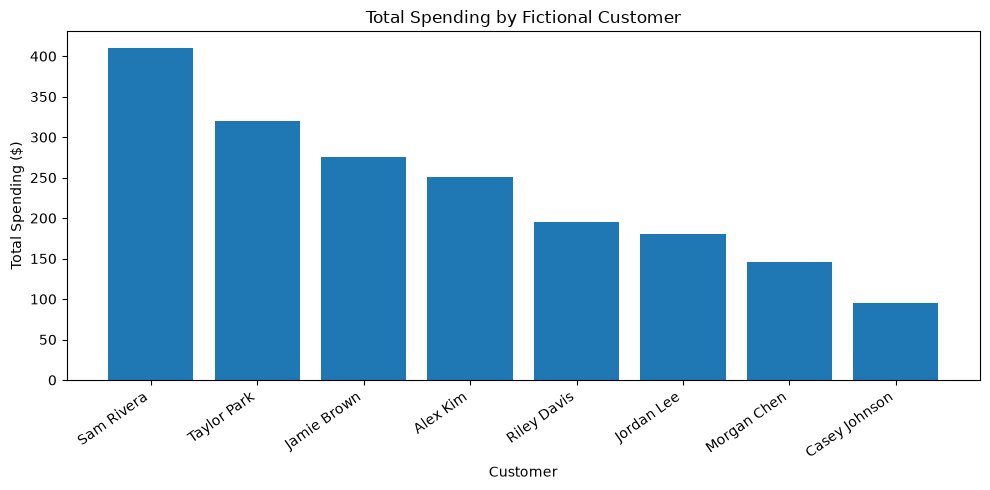

In [5]:
plt.figure(figsize=(10, 5))

plt.bar(sorted_results["name"], sorted_results["total_spent"])

plt.title("Total Spending by Fictional Customer")
plt.xlabel("Customer")
plt.ylabel("Total Spending ($)")
plt.xticks(rotation=35, ha="right")
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

For this chart in particular, what I wanted to do was compare the amount much each customer spent. I sorted them from highest to lowest so that differences would be more visable. From the results, Rivera spent the most at 410.20 USD, while Casey Johnson spent the least at $95.50.

Github: https://github.com/leonhong2007/cs82a-portfolio/tree/main/module6